In [2]:
import pandas as pd
import numpy as np
from google.colab import files
uploaded = files.upload()
df = pd.read_csv("transformed_hr_dataset.csv")

Saving transformed_hr_dataset.csv to transformed_hr_dataset.csv


# **Heatmap**

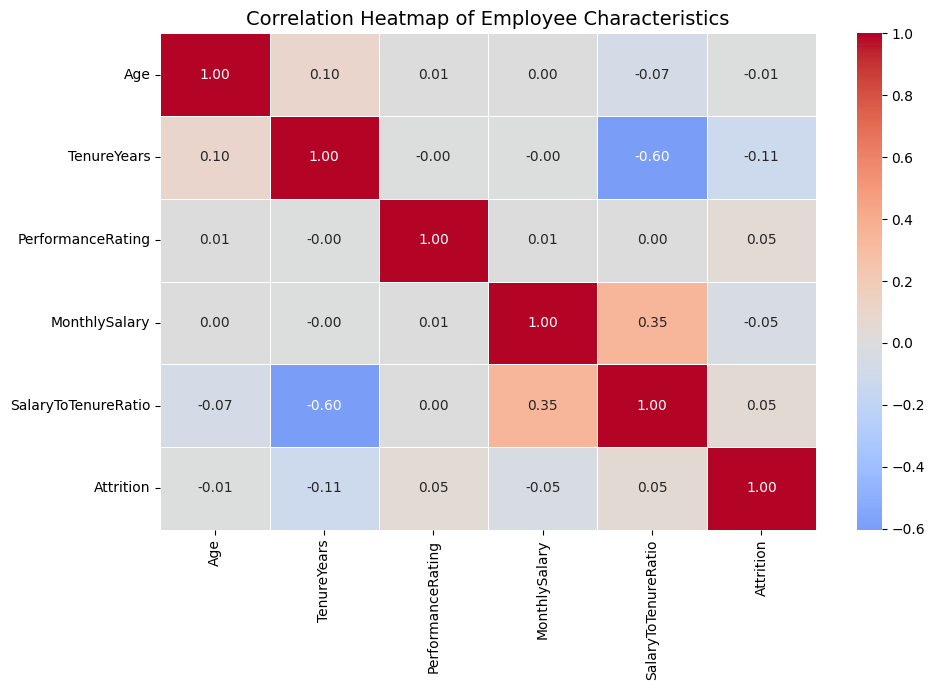

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

selected_columns = [
    'Age',
    'TenureYears',
    'PerformanceRating',
    'MonthlySalary',
    'SalaryToTenureRatio',
    'Attrition'
]

corr_matrix = df[selected_columns].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    center=0
)

plt.title('Correlation Heatmap of Employee Characteristics', fontsize=14)
plt.tight_layout()
plt.show()

# **box blot**

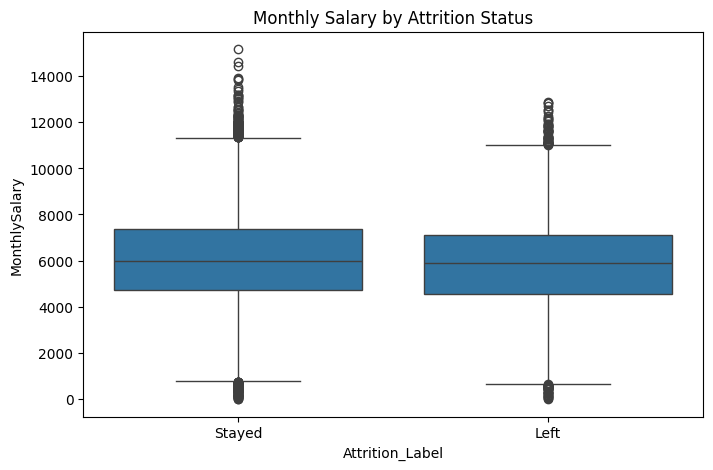

In [6]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='Attrition_Label',
    y='MonthlySalary'
)

plt.title('Monthly Salary by Attrition Status')
plt.show()

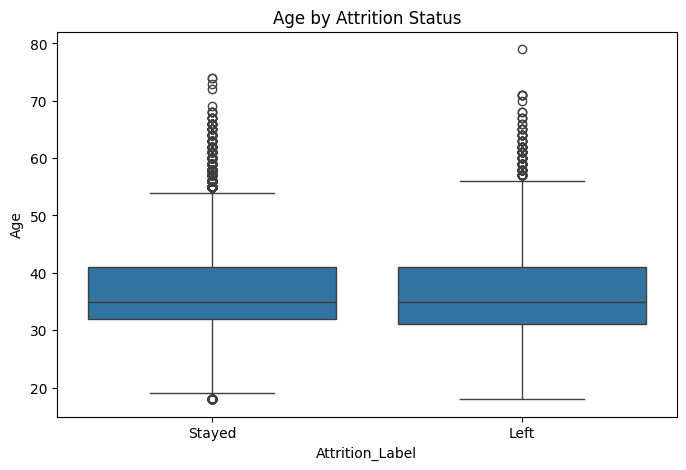

In [7]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='Attrition_Label',
    y='Age'
)

plt.title('Age by Attrition Status')
plt.show()

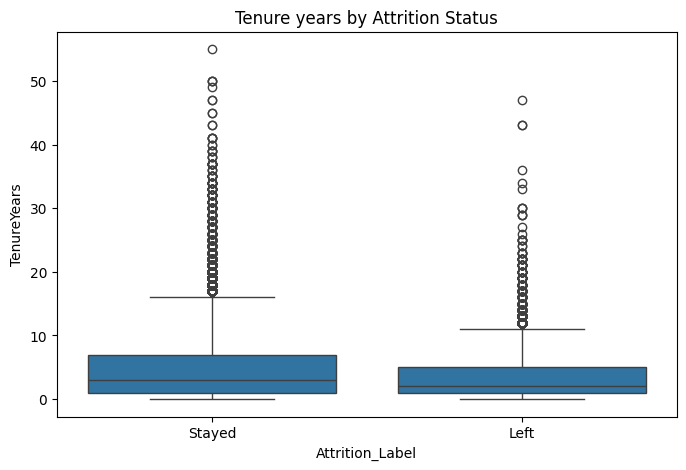

In [8]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='Attrition_Label',
    y='TenureYears'
)

plt.title('Tenure years by Attrition Status')
plt.show()

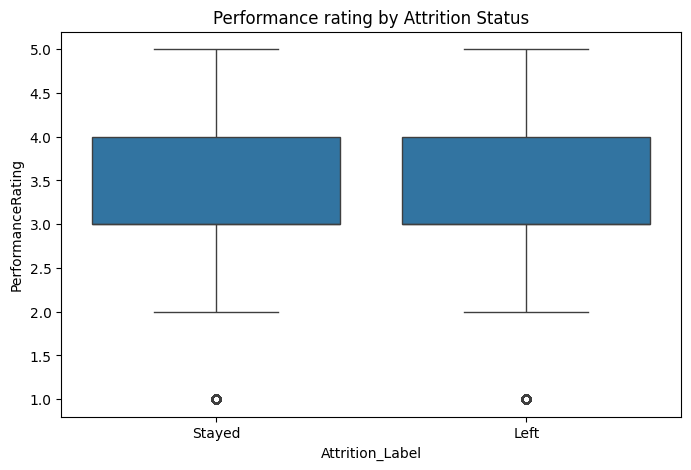

In [9]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='Attrition_Label',
    y='PerformanceRating'
)

plt.title('Performance rating by Attrition Status')
plt.show()

# **bar blot**

In [10]:
job_columns = [
    'JobRole_Data Analyst',
    'JobRole_HR Specialist',
    'JobRole_Manager',
    'JobRole_Sales Exec',
    'JobRole_Software Engineer'
]

df['JobRole'] = (
    df[job_columns]
    .idxmax(axis=1)
    .str.replace('JobRole_', '', regex=False)
)

In [11]:
df['Attrition_Label'] = df['Attrition'].map({
    0: 'Stayed',
    1: 'Left'
})

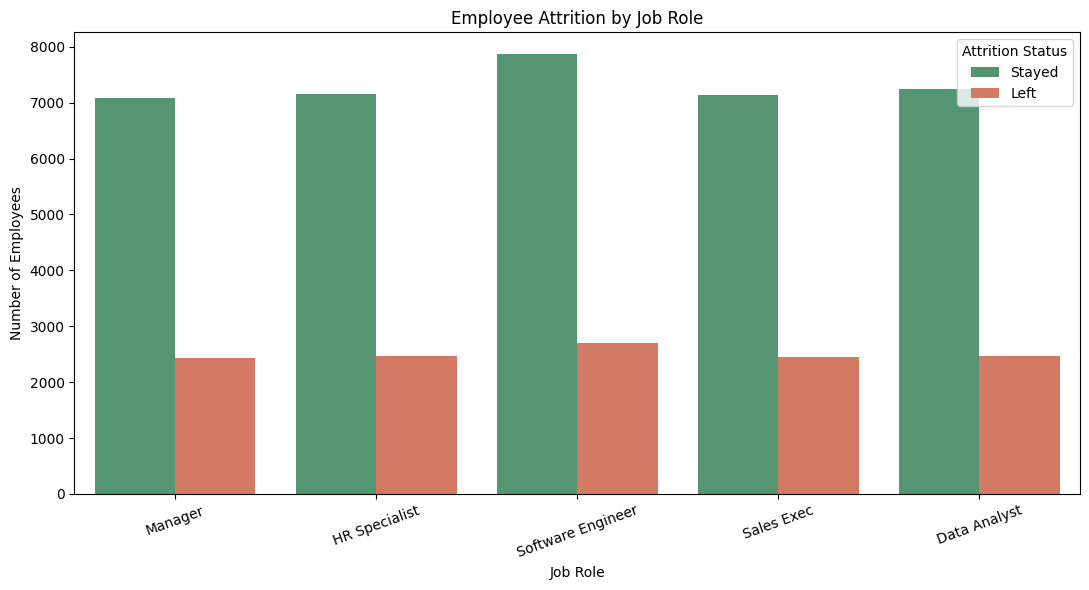

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(11, 6))

sns.countplot(
    data=df,
    x='JobRole',
    hue='Attrition_Label',
    palette=['#4C9F70', '#E76F51']
)

plt.title('Employee Attrition by Job Role')
plt.xlabel('Job Role')
plt.ylabel('Number of Employees')
plt.xticks(rotation=20)
plt.legend(title='Attrition Status')
plt.tight_layout()
plt.show()

In [7]:
tenure_columns = [
    'TenureCategory_Short-term',
    'TenureCategory_Medium-term',
    'TenureCategory_Long-term'
]

df['TenureCategory'] = (
    df[tenure_columns]
    .idxmax(axis=1)
    .str.replace('TenureCategory_', '', regex=False)
)

In [9]:
df['Attrition_Label'] = df['Attrition'].map({
    0: 'Stayed',
    1: 'Left'
})

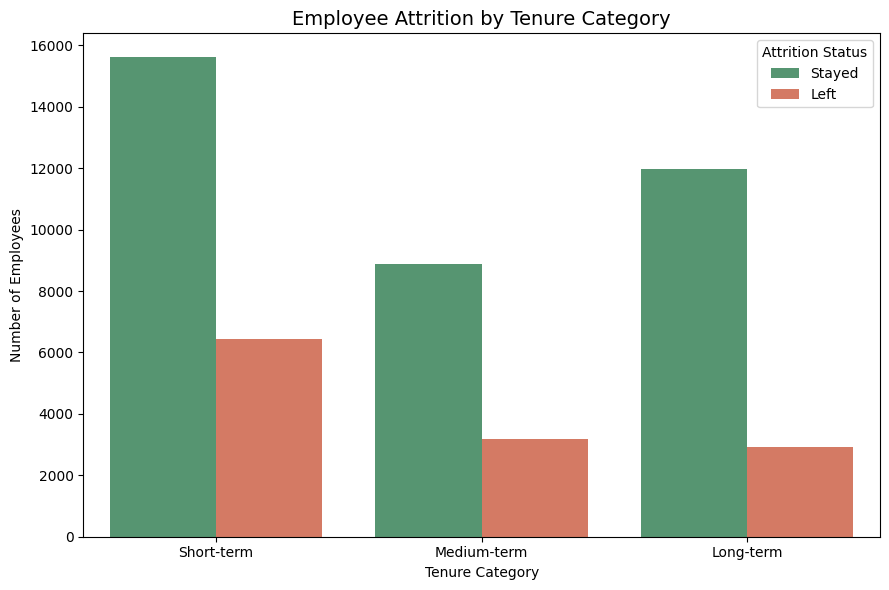

In [10]:
plt.figure(figsize=(9, 6))

sns.countplot(
    data=df,
    x='TenureCategory',
    hue='Attrition_Label',
    order=['Short-term', 'Medium-term', 'Long-term'],
    palette=['#4C9F70', '#E76F51']
)

plt.title('Employee Attrition by Tenure Category', fontsize=14)
plt.xlabel('Tenure Category')
plt.ylabel('Number of Employees')
plt.legend(title='Attrition Status')
plt.tight_layout()
plt.show()

# **interactive dashboard**

In [16]:
!pip install streamlit plotly
!pip install pyngrok

In [17]:
%%writefile app.py

import streamlit as st
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go



# Load dataset
df = pd.read_csv('transformed_hr_dataset.csv')

# Decode categorical columns
category_columns = {
    'Gender': [
        'Gender_Female',
        'Gender_Male',
        'Gender_Non-Binary'
    ],
    'JobRole': [
        'JobRole_Data Analyst',
        'JobRole_HR Specialist',
        'JobRole_Manager',
        'JobRole_Sales Exec',
        'JobRole_Software Engineer'
    ],
    'TenureCategory': [
        'TenureCategory_Short-term',
        'TenureCategory_Medium-term',
        'TenureCategory_Long-term'
    ],
    'SalaryBand': [
        'SalaryBand_Low',
        'SalaryBand_Medium',
        'SalaryBand_High'
    ],
    'AgeGroup': [
        'AgeGroup_Young',
        'AgeGroup_Early Career',
        'AgeGroup_Mid Career',
        'AgeGroup_Experienced',
        'AgeGroup_Senior'
    ]
}

for category, columns in category_columns.items():
    df[category] = (
        df[columns]
        .idxmax(axis=1)
        .str.replace(category + '_', '', regex=False)
    )

# Create readable attrition labels
df['Attrition_Label'] = df['Attrition'].map({
    0: 'Stayed',
    1: 'Left'
})

#.............................................................................

st.set_page_config(
    page_title="HR Attrition Dashboard",
    page_icon="📊",
    layout="wide"
)

st.title("📊 Employee Attrition Dashboard")
st.write("Explore employee characteristics and attrition patterns.")

# Sidebar filters
st.sidebar.header("Filter Employees")

gender_filter = st.sidebar.multiselect(
    "Gender",
    df['Gender'].unique(),
    default=df['Gender'].unique()
)

role_filter = st.sidebar.multiselect(
    "Job Role",
    df['JobRole'].unique(),
    default=df['JobRole'].unique()
)

age_filter = st.sidebar.multiselect(
    "Age Group",
    df['AgeGroup'].unique(),
    default=df['AgeGroup'].unique()
)

tenure_filter = st.sidebar.multiselect(
    "Tenure Category",
    df['TenureCategory'].unique(),
    default=df['TenureCategory'].unique()
)

salary_filter = st.sidebar.multiselect(
    "Salary Band",
    df['SalaryBand'].unique(),
    default=df['SalaryBand'].unique()
)

# Apply filters
filtered_df = df[
    (df['Gender'].isin(gender_filter)) &
    (df['JobRole'].isin(role_filter)) &
    (df['AgeGroup'].isin(age_filter)) &
    (df['TenureCategory'].isin(tenure_filter)) &
    (df['SalaryBand'].isin(salary_filter))
]

#..........................................................................

total = len(filtered_df)

left = (filtered_df['Attrition'] == 1).sum()

stayed = (filtered_df['Attrition'] == 0).sum()

attrition_rate = (
    (left / total) * 100 if total > 0 else 0
)

col1, col2, col3, col4 = st.columns(4)

col1.metric("Total Employees", f"{total:,}")

col2.metric("Employees Left", f"{left:,}")

col3.metric("Employees Stayed", f"{stayed:,}")

col4.metric("Attrition Rate", f"{attrition_rate:.2f}%")

#.............................................................................

st.subheader("Attrition by Job Role")

fig1 = px.histogram(
    filtered_df,
    x='JobRole',
    color='Attrition_Label',
    barmode='group',
    title='Employees Who Stayed vs. Left by Job Role',
    color_discrete_map={
        'Stayed': '#4C9F70',
        'Left': '#E76F51'
    }
)

st.plotly_chart(fig1, use_container_width=True)

#............................................................................

st.subheader("Attrition by Tenure Category")

fig2 = px.histogram(
    filtered_df,
    x='TenureCategory',
    color='Attrition_Label',
    barmode='group',
    category_orders={
        'TenureCategory': [
            'Short-term',
            'Medium-term',
            'Long-term'
        ]
    },
    title='Attrition Across Tenure Categories'
)

st.plotly_chart(fig2, use_container_width=True)

#......................................................................

st.subheader("Attrition by Gender")

fig3 = px.histogram(
    filtered_df,
    x='Gender',
    color='Attrition_Label',
    barmode='group',
    title='Employee Attrition by Gender'
)

st.plotly_chart(fig3, use_container_width=True)

#...........................................................................

st.subheader("Salary Distribution by Attrition")

fig4 = px.box(
    filtered_df,
    x='Attrition_Label',
    y='MonthlySalary',
    color='Attrition_Label',
    title='Monthly Salary: Stayed vs. Left'
)

st.plotly_chart(fig4, use_container_width=True)

#...........................................................................

st.subheader("Attrition by Age Group")

fig5 = px.histogram(
    filtered_df,
    x='AgeGroup',
    color='Attrition_Label',
    barmode='group',
    title='Employee Attrition by Age Group'
)

st.plotly_chart(fig5, use_container_width=True)

#............................................................................

st.subheader("Employee Characteristics Correlation")

corr = filtered_df[
    [
        'Age',
        'TenureYears',
        'PerformanceRating',
        'MonthlySalary',
        'SalaryToTenureRatio',
        'Attrition'
    ]
].corr()

fig6 = px.imshow(
    corr,
    text_auto='.2f',
    color_continuous_scale='RdBu_r',
    zmin=-1,
    zmax=1,
    title='Employee Correlation Heatmap'
)

st.plotly_chart(fig6, use_container_width=True)


Writing app.py
